Code for processing data samples can get messy and hard to maintain; we ideally want our dataset code to be decoupled from our model training code for better readability and modularity. PyTorch provides two data primitives: torch.utils.data.DataLoader and torch.utils.data.Dataset that allow you to use pre-loaded datasets as well as your own data. Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset to enable easy access to the samples.

PyTorch domain libraries provide a number of pre-loaded datasets (such as FashionMNIST) that subclass torch.utils.data.Dataset and implement functions specific to the particular data. They can be used to prototype and benchmark your model. You can find them here: Image Datasets, Text Datasets, and Audio Datasets

Loading a Dataset
Here is an example of how to load the Fashion-MNIST dataset from TorchVision. Fashion-MNIST is a dataset of Zalando's article images consisting of 60,000 training examples and 10,000 test examples. Each example comprises a 28×28 grayscale image and an associated label from one of 10 classes.

We load the FashionMNIST Dataset with the following parameters:

: - root is the path where the train/test data is stored, - train specifies training or test dataset, - download=True downloads the data from the internet if it's not available at root. - transform and target_transform specify the feature and label transformations

In [1]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt


training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

Iterating and Visualizing the Dataset
We can index Datasets manually like a list: training_data[index]. We use matplotlib to visualize some samples in our training data.

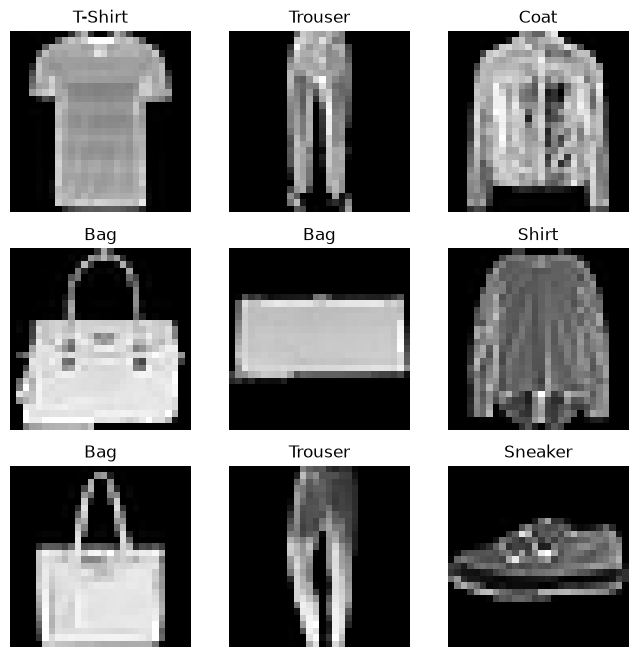

In [2]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

Creating a Custom Dataset for your files
A custom Dataset class must implement three functions: [__init__]{.title-ref}, [__len__]{.title-ref}, and [__getitem__]{.title-ref}. Take a look at this implementation; the FashionMNIST images are stored in a directory img_dir, and their labels are stored separately in a CSV file annotations_file.

In the next sections, we'll break down what's happening in each of these functions.

In [3]:
import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = decode_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label


`__init__`
==========

The \_\_[init](#init__) function is run once when instantiating the
Dataset object. We initialize the directory containing the images, the
annotations file, and both transforms (covered in more detail in the
next section).

The labels.csv file looks like: :


__init__
The __init function is run once when instantiating the Dataset object. We initialize the directory containing the images, the annotations file, and both transforms (covered in more detail in the next section).

The labels.csv file looks like: :

tshirt1.jpg, 0
tshirt2.jpg, 0
......
ankleboot999.jpg, 9

In [4]:
def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
    self.img_labels = pd.read_csv(annotations_file)
    self.img_dir = img_dir
    self.transform = transform
    self.target_transform = target_transform

In [5]:
def __len__(self):
    return len(self.img_labels)

In [6]:
def __getitem__(self, idx):
    img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
    image = decode_image(img_path)
    label = self.img_labels.iloc[idx, 1]
    if self.transform:
        image = self.transform(image)
    if self.target_transform:
        label = self.target_transform(label)
    return image, label

In [7]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


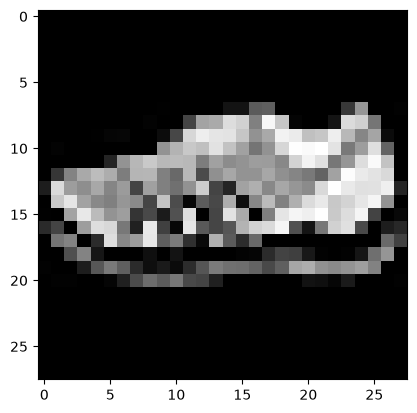

Label: 7


In [8]:
# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

Why a custom Dataset?
FashionMNIST is a ready-made dataset, so PyTorch already knows how to load it. Your own data is usually just a folder of image files plus a label file. PyTorch can't know how to read that, so you write a class that teaches it.

A PyTorch Dataset has to answer two questions:

How many samples are there? → __len__
Give me sample number idx → __getitem__
Once you've defined those, DataLoader can batch, shuffle, and load your data like any built-in dataset.

The data this expects

img_dir/
  img001.jpg
  img002.jpg
  ...
labels.csv
labels.csv has one row per image: the filename, then the label.


img001.jpg,0
img002.jpg,3
img003.jpg,1
Line by line
__init__ runs once, when you create the dataset. It only stores things, and it does not load any images.


self.img_labels = pd.read_csv(annotations_file)  # read the CSV into a table
self.img_dir = img_dir                           # remember where images live
self.transform = transform                       # optional function to apply to images
self.target_transform = target_transform         # optional function to apply to labels
__len__ returns the number of rows in the CSV, which is the number of samples.


return len(self.img_labels)
__getitem__ runs each time something asks for dataset[idx].


img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
Takes row idx, column 0 (the filename), and joins it with the folder to get the full path.


image = decode_image(img_path)
Reads that file from disk into a tensor.


label = self.img_labels.iloc[idx, 1]
Takes row idx, column 1 (the label).


if self.transform: image = self.transform(image)
if self.target_transform: label = self.target_transform(label)
Optionally preprocesses the image (resize, convert to float, normalize) and the label (e.g. one-hot encode). These are skipped if you pass nothing.


return image, label
Returns one (image, label) pair.

Why load images in __getitem__ and not __init__?
Datasets can be huge. If __init__ loaded every image, it would fill your RAM and take a long time to start. Instead, only the small CSV is held in memory. Each image is read from disk only when it's requested, so the DataLoader loads just the batch it needs, and it can do so in parallel with num_workers.

Usage

dataset = CustomImageDataset("labels.csv", "img_dir/", transform=v2.ToDtype(torch.float32, scale=True))
print(len(dataset))
img, label = dataset[0]

loader = DataLoader(dataset, batch_size=64, shuffle=True)
The class does the same job that datasets.FashionMNIST(...) did for you earlier. It just works with your own files.

One note: the notebook snippet uses Dataset without importing it, so you'll need from torch.utils.data import Dataset somewhere above it.